# How robust is Naman's motif tracker? Mouse 720762

**Question.** Naman's tracker (`motif_tracking.py`, branch `naman-mouse720762-states`) finds a library of 9 motifs
in PL5 LFP on this recording. Which of them are real, and which come from how the tracker is set up?

**Two checks**, run with `src/tracker_robustness.py` on the full 2-hour recording
(`720762-20240221-v001.nwb`), for two signals: **PL5 LFP** (Naman's main signal) and **EEG ch13** (frontal, over MOs).

1. **Settings sweep (step 2).** Rerun the tracker with independent (non-overlapping) windows, shorter and longer
   sliding baselines, and longer detection windows. A real motif should survive all of them.
2. **Surrogates (step 1).** Run the whole tracker on fake envelopes that have no motifs, and see what it "finds":
   - **shared-phase**: phase-randomized with the same random phases in every band. Keeps each band's spectrum
     *and* the linear correlations between bands. This is a correlated Gaussian process.
   - **independent-phase**: different phases per band. Keeps each band's spectrum, but removes everything
     shared across bands.

   Each surrogate is made within each of the tracker's segments (cut at isoflurane onset, end of induction and
   stimulus block edges), then goes through the full tracker: global z-score, sliding baseline, window
   detection, linking and library.

The tracker code is copied unchanged into `src/naman/`. To keep runs fast, the checks skip Naman's per-window
measurement step (`mt.measure`) and compute *presence* with the same rule it uses: a window counts as
"present" if it has a detected candidate with |cos| ≥ 0.8 to the motif's template. The default run reproduces
Naman's library exactly (9 motifs; M1 present in 81% of windows, M2 in 25%).

In [1]:
%matplotlib inline
import os, sys, json, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
from src import tracker_robustness as tr
from src.naman import motif_tracking as mt
from src.naman.state_motifs import BANDS
get_ipython().run_line_magic("matplotlib", "inline")   # state_motifs calls matplotlib.use("Agg") on import

OUT = tr.OUT
SIGS = list(tr.SIGNALS)
C = {"lfp_PL5": "#2a78d6", "eeg13": "#eb6834"}            # categorical slots 1, 2
LABEL = {"lfp_PL5": "PL5 LFP (prelimbic L5)", "eeg13": "EEG ch13 (frontal, MOs)"}
INK, INK2, MUTED, GRID, BASE_LINE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
STIM, VIS = "#eda100", "#1baf7a"
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])  # blue - gray - red
BAND_LBL = [f"{a:g}–{b:g}" for a, b in BANDS]

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": BASE_LINE, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "figure.facecolor": "white",
})

cfg = tr.BASE
data = {k: tr.load(k) for k in SIGS}
info = data["lfp_PL5"]["info"]
sig = {k: mt.prepare_arrays(k, d["info"], d["t"], d["env"], cfg) for k, d in data.items()}

sweep = pd.read_csv(OUT / "sweep_summary.csv")
motifs = pd.read_csv(OUT / "sweep_motifs.csv")
motifs["u"] = motifs.template.map(lambda s: np.array(json.loads(s)))
default = motifs[motifs.config.str.startswith("default")]
T = {k: {r.motif: r.u for r in default[default.signal == k].itertuples()} for k in SIGS}
# sign-align EEG M2 to PL5 M2 so the two are drawn the same way up
if T["eeg13"]["M2"] @ T["lfp_PL5"]["M2"] < 0:
    T["eeg13"]["M2"] = -T["eeg13"]["M2"]

def events(ax, label=False):
    for i, (_, a, b) in enumerate(info.stim_blocks):
        ax.axvspan(a / 60, b / 60, color=STIM, alpha=0.15, lw=0)
    for _, a, b in info.visual_blocks:
        ax.axvspan(a / 60, b / 60, color=VIS, alpha=0.15, lw=0)
    ax.axvline(info.iso_on / 60, color=INK, lw=1, ls="--")
    ax.axvline(info.induction_end / 60, color=INK, lw=1, ls=":")

EVENT_HANDLES = [Patch(color=STIM, alpha=0.3, label="electrical stimulation"),
                 Patch(color=VIS, alpha=0.3, label="visual stimulation"),
                 Line2D([], [], color=INK, lw=1, ls="--", label="isoflurane on"),
                 Line2D([], [], color=INK, lw=1, ls=":", label="end of induction")]
print(f"recording {info.t_start/60:.0f}-{info.iso_off/60:.0f} min; iso on at {info.iso_on/60:.1f} min; "
      f"{len(sig['lfp_PL5'].t)} s at 1 Hz, {len(BANDS)} bands")

recording 0-119 min; iso on at 54.9 min; 7088 s at 1 Hz, 10 bands


## 1. The data the tracker sees

Top: isoflurane level. Below it, for PL5: the band envelopes z-scored over the whole recording, then the
**residual** the tracker actually runs detection on: (envelope − sliding 5-min baseline) / sliding SD. The
residual removes the slow changes (the big awake → isoflurane shift is clear in the z-scored panel and gone in
the residual). Bottom: the residual for EEG ch13.

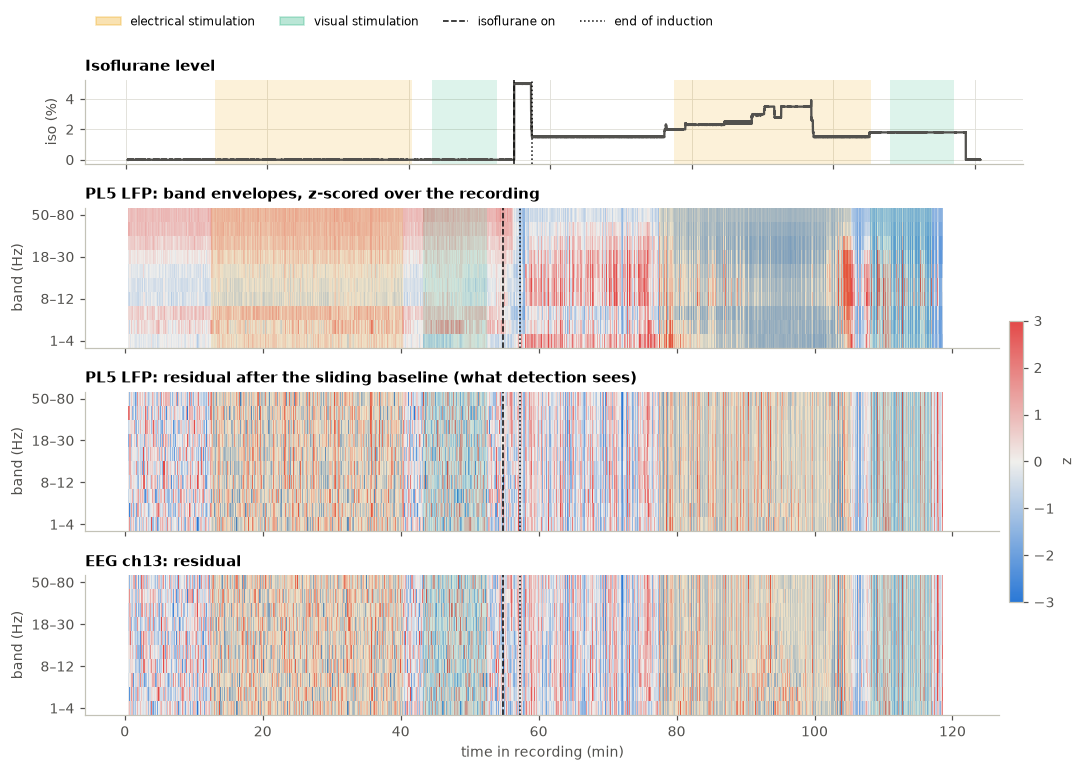

In [2]:
fig, axes = plt.subplots(4, 1, figsize=(11, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [0.6, 1, 1, 1], "hspace": 0.35})
ax = axes[0]
ax.plot(info.iso_t / 60, info.iso_level, color=INK2, lw=1.5)
ax.set_ylabel("iso (%)"); ax.set_title("Isoflurane level"); events(ax)
ext = lambda s: [s.t[0] / 60, s.t[-1] / 60, -0.5, len(BANDS) - 0.5]
panels = [("lfp_PL5", "Z", "PL5 LFP: band envelopes, z-scored over the recording"),
          ("lfp_PL5", "resid", "PL5 LFP: residual after the sliding baseline (what detection sees)"),
          ("eeg13", "resid", "EEG ch13: residual")]
for ax, (k, field, title) in zip(axes[1:], panels):
    s = sig[k]
    im = ax.imshow(getattr(s, field).T, aspect="auto", origin="lower", cmap=DIV, vmin=-3, vmax=3,
                   extent=ext(s), interpolation="nearest")
    ax.set_yticks(range(len(BANDS))[::3]); ax.set_yticklabels(BAND_LBL[::3]); ax.set_ylabel("band (Hz)")
    ax.set_title(title); ax.grid(False); events(ax)
axes[-1].set_xlabel("time in recording (min)")
cb = fig.colorbar(im, ax=axes[1:], fraction=0.015, pad=0.01); cb.set_label("z")
axes[0].legend(handles=EVENT_HANDLES, ncol=4, loc="upper left", bbox_to_anchor=(0, 1.9), fontsize=8)
plt.show()

## 2. The default library: M1, M2 and the rest

Each motif is a direction in the 10-band space (a unit vector; the sign is arbitrary, so a motif and its
opposite are the same axis). Left: **M1** for both signals. Middle: **M2**, with EEG flipped to match PL5.
Right: M3–M9 from PL5, which each appear in only a few windows.

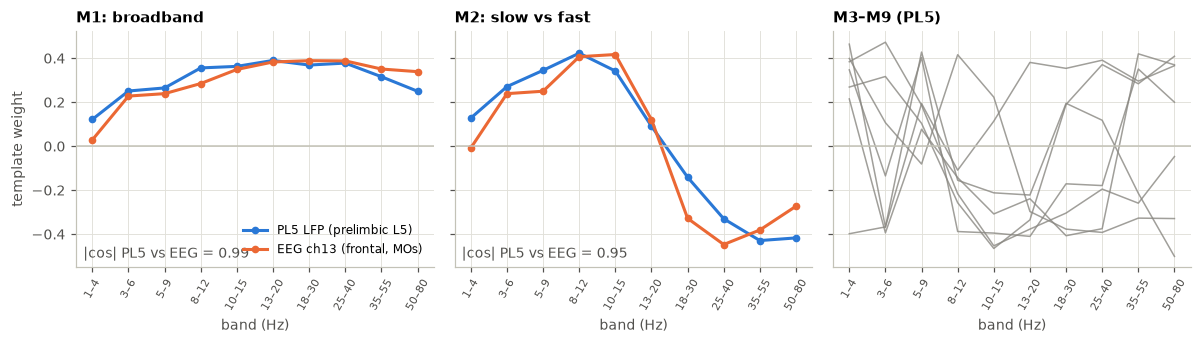

,signal,motif,track windows,track share,present share,broadband
13,lfp_PL5,M1,92,0.81,0.81,True
14,lfp_PL5,M2,22,0.19,0.25,False
15,lfp_PL5,M3,4,0.04,0.04,False
16,lfp_PL5,M4,4,0.04,0.09,False
17,lfp_PL5,M5,4,0.04,0.12,False
18,lfp_PL5,M6,4,0.04,0.05,False
19,lfp_PL5,M7,3,0.03,0.04,False
20,lfp_PL5,M8,3,0.03,0.04,False
21,lfp_PL5,M9,3,0.03,0.05,False
45,eeg13,M1,72,0.63,0.70,True


In [3]:
x = np.arange(len(BANDS))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, m, title in [(axes[0], "M1", "M1: broadband"),
                     (axes[1], "M2", "M2: slow vs fast")]:
    for k in SIGS:
        ax.plot(x, T[k][m], color=C[k], marker="o", ms=4, label=LABEL[k])
    ax.axhline(0, color=BASE_LINE, lw=1); ax.set_title(title)
cos2 = abs(T["lfp_PL5"]["M2"] @ T["eeg13"]["M2"]); cos1 = abs(T["lfp_PL5"]["M1"] @ T["eeg13"]["M1"])
axes[0].text(0.02, 0.04, f"|cos| PL5 vs EEG = {cos1:.2f}", transform=axes[0].transAxes, color=INK2)
axes[1].text(0.02, 0.04, f"|cos| PL5 vs EEG = {cos2:.2f}", transform=axes[1].transAxes, color=INK2)
axes[0].legend(loc="lower right", fontsize=8)
for m, u in T["lfp_PL5"].items():
    if m not in ("M1", "M2"):
        axes[2].plot(x, u, color=MUTED, lw=1, alpha=0.8)
axes[2].axhline(0, color=BASE_LINE, lw=1); axes[2].set_title("M3–M9 (PL5)")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(BAND_LBL, rotation=60, fontsize=7); ax.set_xlabel("band (Hz)")
axes[0].set_ylabel("template weight")
plt.tight_layout(); plt.show()

d = default.drop(columns=["template", "u", "config", "cos_to_ref"]).copy()
d[["life_frac", "present_frac"]] = d[["life_frac", "present_frac"]].round(2)
d.rename(columns={"life_windows": "track windows", "life_frac": "track share", "present_frac": "present share"})

## 3. Step 2: do the motifs survive different settings?

The tracker was rerun six ways. Each row is one way; blue bars are PL5, orange bars are EEG.
- **Left:** how many motifs it kept. If this jumps around, the count isn't trustworthy.
- **Middle / right:** how often M1 and M2 were found (share of 5-min windows). "not found" means no motif in that
  run matched the default shape (|cos| ≥ 0.9).

What to look for: M1 and M2 stay about the same in every row, while the motif count swings from 1 to 11.

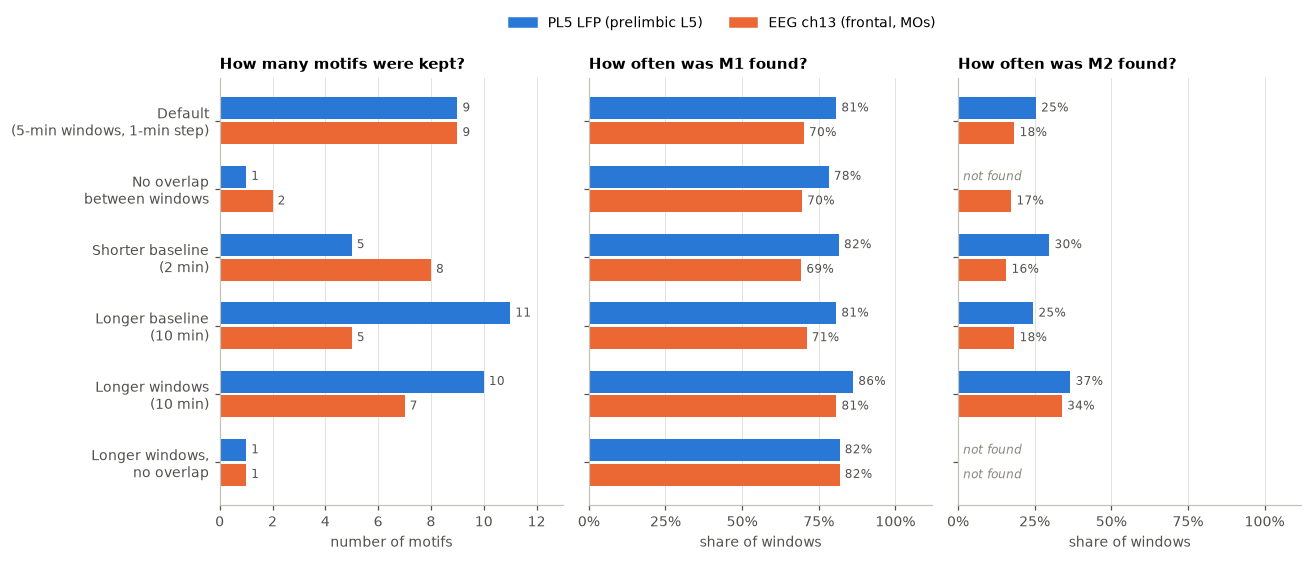

,signal,config,library,M1_cos,M1_present,M2_cos,M2_present
0,eeg13,baseline 120 s,8,1.0,0.69,0.95,0.16
1,eeg13,baseline 600 s,5,1.0,0.71,0.99,0.18
2,eeg13,default (300/300/60),9,1.0,0.70,1.00,0.18
3,eeg13,non-overlapping (step 300),2,1.0,0.70,0.99,0.17
4,eeg13,window 600 s,7,1.0,0.81,0.98,0.34
5,eeg13,"window 600, non-overlapping",1,1.0,0.82,0.12,0.82
6,lfp_PL5,baseline 120 s,5,1.0,0.82,0.98,0.30
7,lfp_PL5,baseline 600 s,11,1.0,0.81,0.99,0.25
8,lfp_PL5,default (300/300/60),9,1.0,0.81,1.00,0.25
9,lfp_PL5,non-overlapping (step 300),1,1.0,0.78,0.07,0.78


In [4]:
from matplotlib.ticker import PercentFormatter
CONFIGS = list(tr.SWEEP)
NICE = {"default (300/300/60)": "Default\n(5-min windows, 1-min step)",
        "non-overlapping (step 300)": "No overlap\nbetween windows",
        "baseline 120 s": "Shorter baseline\n(2 min)",
        "baseline 600 s": "Longer baseline\n(10 min)",
        "window 600 s": "Longer windows\n(10 min)",
        "window 600, non-overlapping": "Longer windows,\nno overlap"}
ref = {k: T[k] for k in SIGS}
rows = []
for (k, c), g in motifs.groupby(["signal", "config"]):
    row = {"signal": k, "config": c, "library": len(g)}
    for m in ("M1", "M2"):
        cs = g.u.map(lambda u: abs(u @ ref[k][m]))
        i = cs.idxmax()
        row[f"{m}_cos"], row[f"{m}_present"] = cs[i], g.present_frac[i]
    rows.append(row)
sw = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(12, 5), sharey=True)
y = np.arange(len(CONFIGS))[::-1].astype(float)
h = 0.36
panels = [("library", "How many motifs were kept?", "number of motifs", 13),
          ("M1_present", "How often was M1 found?", "share of windows", 1.12),
          ("M2_present", "How often was M2 found?", "share of windows", 1.12)]
for ax, (col, title, xl, xmax) in zip(axes, panels):
    for j, k in enumerate(SIGS):
        s = sw[sw.signal == k].set_index("config").loc[CONFIGS]
        vals = s[col].to_numpy(float)
        found = np.ones(len(vals), bool) if col == "library" else s[col.replace("present", "cos")].to_numpy() >= 0.9
        vals = np.where(found, vals, 0)
        yy = y + (h / 2 if j == 0 else -h / 2)
        ax.barh(yy, vals, height=h - 0.04, color=C[k], label=LABEL[k])
        for yi, v, f in zip(yy, vals, found):
            txt = (f"{v:.0f}" if col == "library" else f"{v:.0%}") if f else "not found"
            ax.text(v + xmax * 0.015, yi, txt, va="center", fontsize=8, color=INK2 if f else MUTED,
                    style="normal" if f else "italic")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_xlim(0, xmax)
    ax.grid(axis="y", visible=False)
    if col != "library":
        ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
axes[0].set_yticks(y); axes[0].set_yticklabels([NICE[c] for c in CONFIGS])
handles = [Patch(color=C[k], label=LABEL[k]) for k in SIGS]
fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.55, 1.02), fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()
sw.round(2).sort_values(["signal", "config"])

## 4. What is M1? Overall power going up and down

M1 has every band with the same sign. Projecting the residual onto M1 gives almost the same signal as simply
averaging the residual across bands, and M1 is close to the first principal component of the residual. So M1 is
mostly "all bands up together / all down together", not a pattern across frequencies.

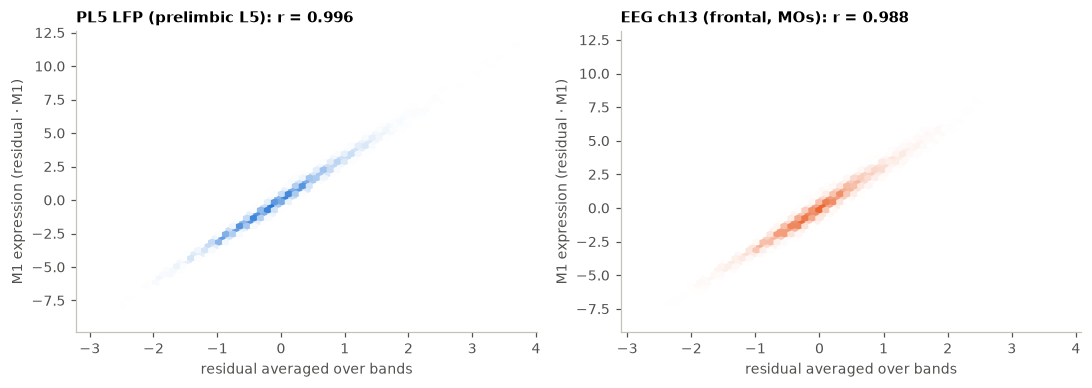

,"r(M1 expression, mean of bands)","|cos|(M1, PC1)",PC1 share of variance,"|cos|(M2, PC1)","|cos|(M2, PC2)","|cos|(M2, PC3)","PC2, PC3 share"
signal,,,,,,,
PL5 LFP (prelimbic L5),0.996,0.987,0.574,0.079,0.814,0.514,"0.089, 0.074"
"EEG ch13 (frontal, MOs)",0.988,0.981,0.489,0.019,0.512,0.849,"0.107, 0.087"


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
rows = []
for ax, k in zip(axes, SIGS):
    R = sig[k].resid[np.isfinite(sig[k].resid).all(axis=1)]
    e1 = R @ T[k]["M1"]; avg = R.mean(axis=1)
    r = np.corrcoef(e1, avg)[0, 1]
    w, V = np.linalg.eigh(np.cov(R.T)); w, V = w[::-1], V[:, ::-1]
    rows.append({"signal": LABEL[k], "r(M1 expression, mean of bands)": r,
                 "|cos|(M1, PC1)": abs(V[:, 0] @ T[k]["M1"]), "PC1 share of variance": w[0] / w.sum(),
                 "|cos|(M2, PC1)": abs(V[:, 0] @ T[k]["M2"]), "|cos|(M2, PC2)": abs(V[:, 1] @ T[k]["M2"]),
                 "|cos|(M2, PC3)": abs(V[:, 2] @ T[k]["M2"]),
                 "PC2, PC3 share": f"{w[1] / w.sum():.3f}, {w[2] / w.sum():.3f}"})
    ax.hexbin(avg, e1, gridsize=60, cmap=LinearSegmentedColormap.from_list("seq", ["#ffffff", C[k]]), mincnt=1)
    ax.set_title(f"{LABEL[k]}: r = {r:.3f}"); ax.set_xlabel("residual averaged over bands")
    ax.set_ylabel("M1 expression (residual · M1)"); ax.grid(False)
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("signal").round(3)

## 5. When are M1 and M2 present?

Each marker is a 5-min tracker window (default settings) where M1 or M2 was detected. The bottom panel shows the
M2 expression (residual · M2, smoothed over 60 s) for both signals on the same axis, to see whether the motif goes
up and down together in PL5 and EEG.

Detected candidates for the default run are cached in `cands_<signal>.pkl` (the first run takes about 5 min per signal).

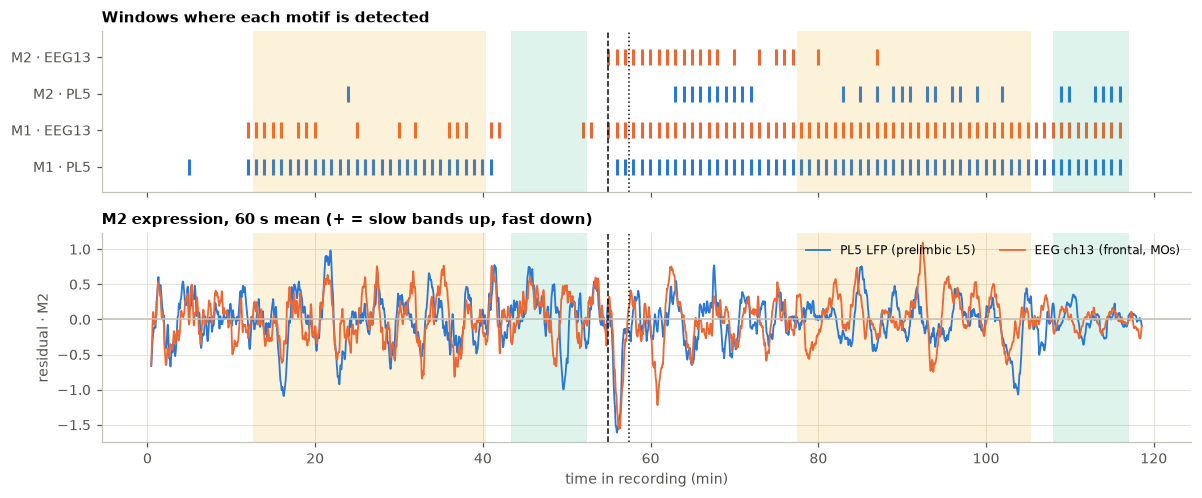

Correlation of 60-s M2 expression, PL5 vs EEG13:
  all        r = 0.50  (7088 s)
  awake      r = 0.51  (3267 s)
  isoflurane r = 0.33  (3673 s)


,share of awake windows,share of isoflurane windows
M1 · PL5 LFP (prelimbic L5),0.60,1.00
"M1 · EEG ch13 (frontal, MOs)",0.35,1.00
M2 · PL5 LFP (prelimbic L5),0.02,0.47
"M2 · EEG ch13 (frontal, MOs)",0.00,0.31


In [6]:
cands = {}
for k in SIGS:
    f = OUT / f"cands_{k}.pkl"
    if f.exists():
        cands[k] = pd.read_pickle(f)
    else:
        cands[k] = mt.link(mt.window_candidates(sig[k], cfg), cfg)
        cands[k].to_pickle(f)
centres = mt.window_starts(sig["lfp_PL5"], cfg) + cfg.window / 2

def present(k, m):
    c = cands[k]
    hit = np.abs(np.stack(c.axis.to_numpy()) @ T[k][m]) >= cfg.link_cos
    return np.isin(np.arange(len(centres)), c.window[hit].unique())

def state(t):
    return np.where(t < info.iso_on, "awake", np.where(t >= info.induction_end, "isoflurane", "induction"))

fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ax = axes[0]
yl = []
for i, (k, m) in enumerate([(k, m) for m in ("M1", "M2") for k in SIGS]):
    p = present(k, m)
    ax.scatter(centres[p] / 60, np.full(p.sum(), i), color=C[k], marker="|", s=120, lw=2)
    yl.append(f"{m} · {'PL5' if k == 'lfp_PL5' else 'EEG13'}")
ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl); ax.set_ylim(-0.7, len(yl) - 0.3)
ax.set_title("Windows where each motif is detected"); ax.grid(False); events(ax)
ax = axes[1]
expr = {}
for k in SIGS:
    s = sig[k]
    # the two signals' timestamps differ by ~15 ms, so index by whole seconds to line them up
    e = pd.Series(s.resid @ T[k]["M2"], index=np.round(s.t).astype(int))
    e = e[~e.index.duplicated()].rolling(60, center=True, min_periods=30).mean()
    expr[k] = e
    ax.plot(e.index / 60, e.to_numpy(), color=C[k], lw=1.2, label=LABEL[k])
ax.axhline(0, color=BASE_LINE, lw=1); events(ax)
ax.set_title("M2 expression, 60 s mean (+ = slow bands up, fast down)"); ax.set_ylabel("residual · M2")
ax.set_xlabel("time in recording (min)"); ax.legend(loc="upper right", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

j = pd.concat(expr, axis=1).dropna()
st = state(j.index.to_numpy())
print("Correlation of 60-s M2 expression, PL5 vs EEG13:")
for name in ("all", "awake", "isoflurane"):
    sel = np.ones(len(j), bool) if name == "all" else st == name
    print(f"  {name:10s} r = {np.corrcoef(j.iloc[sel, 0], j.iloc[sel, 1])[0, 1]:.2f}  ({sel.sum()} s)")
stw = state(centres)
pd.DataFrame({f"{m} · {LABEL[k]}": {s_: present(k, m)[stw == s_].mean() for s_ in ("awake", "isoflurane")}
              for m in ("M1", "M2") for k in SIGS}).T.round(2).rename(columns=lambda c: f"share of {c} windows")

## 6. Step 1: does fake data produce the same motifs?

The tracker was run on 20 fake versions of each signal (default settings):
- **Correlated fake data** (10 runs): keeps how much each band varies *and* how the bands rise and fall together.
  Everything else is scrambled.
- **Uncorrelated fake data** (10 runs): keeps how much each band varies, but the bands are independent.

Each row below is one real motif. The **colored diamond** is how often the tracker found it in the real data.
The **gray dots** are how often it found a motif of the same shape (|cos| ≥ 0.8) in each correlated fake run, and
the **gray band** spans their range. **Hollow circles** are the uncorrelated fake runs (0% means nothing of that
shape was found).

How to read it: a diamond inside the gray band means fake data produces that motif just as often, so the real
motif is explained by the bands' correlations. A diamond to the right of the band would be a real motif beyond that.

In [7]:
SUR_READY = (OUT / "surrogate_comparison.csv").exists()
if not SUR_READY:
    print("Surrogate run still in progress: rerun this notebook once data/out/tracker_robustness/720762/"
          "surrogate_comparison.csv exists. The cells below are skipped until then.")

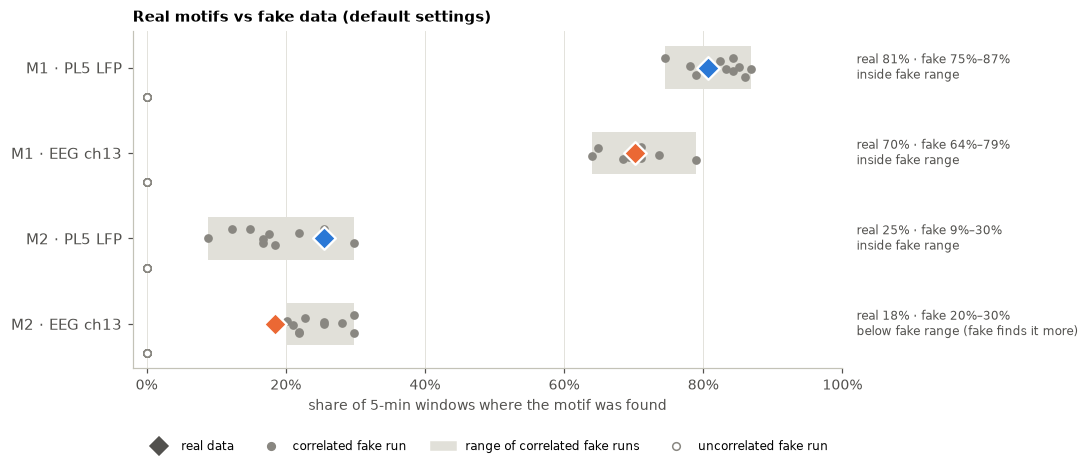

In [8]:
if SUR_READY:
    from matplotlib.ticker import PercentFormatter
    runs = pd.read_csv(OUT / "surrogate_runs.csv")
    smot = pd.read_csv(OUT / "surrogate_motifs.csv")
    smot["u"] = smot.template.map(lambda s: np.array(json.loads(s)))
    comp = pd.read_csv(OUT / "surrogate_comparison.csv")
    sur_cfgs = [c for c in tr.SWEEP if c in set(runs.config)]
    real = motifs[motifs.config.isin(sur_cfgs)]
    c0 = sur_cfgs[0]
    nrep = int(runs.rep.max()) + 1

    def matched(k, m, mode, c=c0):
        # best presence per fake run among motifs shaped like the real motif m (0 if none)
        s = smot[(smot.signal == k) & (smot.config == c) & (smot["mode"] == mode)]
        s = s[s.u.map(lambda u: abs(u @ T[k][m])) >= 0.8]
        return s.groupby("rep").present_frac.max().reindex(range(nrep), fill_value=0.0).to_numpy()

    items = [(k, m) for m in ("M1", "M2") for k in SIGS]
    fig, ax = plt.subplots(figsize=(10, 4.4))
    rng = np.random.default_rng(1)
    for i, (k, m) in enumerate(items):
        yi = len(items) - 1 - i
        r = real[(real.signal == k) & (real.config == c0)]
        cs = r.u.map(lambda u: abs(u @ T[k][m]))
        real_p = r.present_frac[cs.idxmax()]
        sh, ind = matched(k, m, "shared"), matched(k, m, "independent")
        ax.barh(yi, sh.max() - sh.min(), left=sh.min(), height=0.5, color=GRID, zorder=1)
        ax.scatter(sh, yi + rng.uniform(-0.12, 0.12, nrep), s=22, color=MUTED, zorder=2)
        ax.scatter(ind, np.full(nrep, yi - 0.34), s=22, facecolor="white", edgecolor=MUTED, lw=1, zorder=2)
        ax.scatter(real_p, yi, marker="D", s=110, color=C[k], edgecolor="white", lw=1.5, zorder=4)
        inside = sh.min() <= real_p <= sh.max()
        ax.text(1.02, yi, f"real {real_p:.0%} · fake {sh.min():.0%}–{sh.max():.0%}"
                          f"\n{'inside fake range' if inside else ('above fake range' if real_p > sh.max() else 'below fake range (fake finds it more)')}",
                va="center", fontsize=8, color=INK2, transform=ax.get_yaxis_transform())
    ax.set_yticks(range(len(items))[::-1])
    ax.set_yticklabels([f"{m} · {'PL5 LFP' if k == 'lfp_PL5' else 'EEG ch13'}" for k, m in items], fontsize=10)
    ax.set_xlim(-0.02, 1); ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("share of 5-min windows where the motif was found")
    ax.set_title("Real motifs vs fake data (default settings)")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Line2D([], [], marker="D", ls="", color=INK2, ms=8, label="real data"),
                       Line2D([], [], marker="o", ls="", color=MUTED, ms=5, label="correlated fake run"),
                       Patch(color=GRID, label="range of correlated fake runs"),
                       Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=MUTED, ms=5,
                              label="uncorrelated fake run")],
              loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=8)
plt.tight_layout(); plt.show() if SUR_READY else None

In [9]:
if SUR_READY:
    lib = runs.groupby(["signal", "config", "mode"]).agg(sur_library_median=("library", "median"),
                                                         sur_library_max=("library", "max"),
                                                         sur_candidates_median=("candidates", "median"),
                                                         n=("rep", "count")).reset_index()
    real_lib = real.groupby(["signal", "config"]).size().rename("real_library").reset_index()
    real_cand = comp[comp.motif == "(candidates)"].groupby(["signal", "config"]).real.first().rename("real_candidates").reset_index()
lib.merge(real_lib).merge(real_cand) if SUR_READY else None

,signal,config,mode,sur_library_median,sur_library_max,sur_candidates_median,n,real_library,real_candidates
0,eeg13,default (300/300/60),independent,0.0,1,33.5,10,9,160.0
1,eeg13,default (300/300/60),shared,6.5,10,170.0,10,9,160.0
2,eeg13,non-overlapping (step 300),independent,0.0,0,6.0,10,2,29.0
3,eeg13,non-overlapping (step 300),shared,2.0,3,33.5,10,2,29.0
4,lfp_PL5,default (300/300/60),independent,0.5,2,29.0,10,9,185.0
5,lfp_PL5,default (300/300/60),shared,7.5,10,195.5,10,9,185.0
6,lfp_PL5,non-overlapping (step 300),independent,0.0,0,5.5,10,1,34.0
7,lfp_PL5,non-overlapping (step 300),shared,2.0,3,41.5,10,1,34.0


### Do the surrogates produce an M1-like motif?

If the shared-phase surrogates (which keep the correlations between bands) produce a frequently present motif
that looks like M1, then M1 comes from the correlation between bands and isn't a separate pattern. Each dot is
one surrogate library motif: its |cos| to the real M1 against its presence.

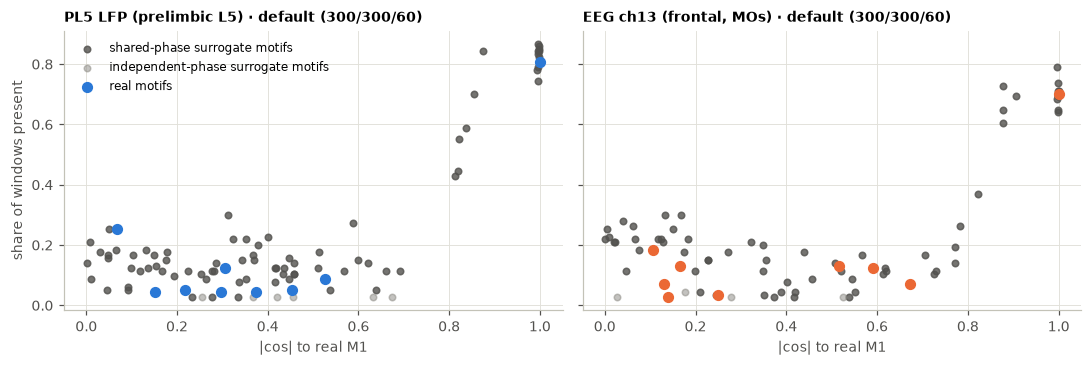

Surrogate motifs matching each real motif's shape (|cos| >= 0.8); p = share of runs whose best match is at least as present as the real motif.


,signal,config,motif,surrogate,real presence,runs with a matching motif,"matched presence (median, max)",p (surrogate ≥ real)
0,lfp_PL5,default (300/300/60),M1,shared,0.807,10/10,"0.84, 0.87",0.727
1,lfp_PL5,default (300/300/60),M1,independent,0.807,0/10,-,0.091
2,lfp_PL5,default (300/300/60),M2,shared,0.254,10/10,"0.17, 0.30",0.273
3,lfp_PL5,default (300/300/60),M2,independent,0.254,0/10,-,0.091
4,eeg13,default (300/300/60),M1,shared,0.702,10/10,"0.70, 0.79",0.545
5,eeg13,default (300/300/60),M1,independent,0.702,0/10,-,0.091
6,eeg13,default (300/300/60),M2,shared,0.184,10/10,"0.24, 0.30",1.000
7,eeg13,default (300/300/60),M2,independent,0.184,0/10,-,0.091
8,lfp_PL5,non-overlapping (step 300),M1,shared,0.783,10/10,"0.85, 0.87",0.909
9,lfp_PL5,non-overlapping (step 300),M1,independent,0.783,0/10,-,0.091


In [10]:
if SUR_READY:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
    for ax, k in zip(axes, SIGS):
        s = smot[(smot.signal == k) & (smot.config == sur_cfgs[0])]
        for mode, col in (("shared", INK2), ("independent", MUTED)):
            q = s[s["mode"] == mode]
            ax.scatter(q.u.map(lambda u: abs(u @ T[k]["M1"])), q.present_frac, s=18, color=col,
                       alpha=0.8 if mode == "shared" else 0.5, label=f"{mode}-phase surrogate motifs")
        r = real[(real.signal == k) & (real.config == sur_cfgs[0])]
        ax.scatter(r.u.map(lambda u: abs(u @ T[k]["M1"])), r.present_frac, s=40, color=C[k], label="real motifs", zorder=3)
        ax.set_xlabel("|cos| to real M1"); ax.set_title(f"{LABEL[k]} · {sur_cfgs[0]}", fontsize=9)
    axes[0].set_ylabel("share of windows present"); axes[0].legend(fontsize=8, loc="upper left")
    plt.tight_layout(); plt.show()

    rows = []
    for c in sur_cfgs:
        for k in SIGS:
            for m in ("M1", "M2"):
                r = real[(real.signal == k) & (real.config == c)]
                cs = r.u.map(lambda u: abs(u @ T[k][m]))
                real_p = r.present_frac[cs.idxmax()] if cs.max() >= 0.9 else np.nan
                for mode in ("shared", "independent"):
                    s = smot[(smot.signal == k) & (smot.config == c) & (smot["mode"] == mode)]
                    s = s[s.u.map(lambda u: abs(u @ T[k][m])) >= 0.8]
                    best = s.groupby("rep").present_frac.max().reindex(range(int(runs.rep.max()) + 1), fill_value=0.0)
                    rows.append({"signal": k, "config": c, "motif": m, "surrogate": mode, "real presence": real_p,
                                 "runs with a matching motif": f"{(best > 0).sum()}/{len(best)}",
                                 "matched presence (median, max)": f"{best[best > 0].median():.2f}, {best.max():.2f}" if (best > 0).any() else "-",
                                 "p (surrogate ≥ real)": (1 + (best >= real_p).sum()) / (1 + len(best)) if real_p == real_p else np.nan})
    print("Surrogate motifs matching each real motif's shape (|cos| >= 0.8); p = share of runs whose best match "
          "is at least as present as the real motif.")
pd.DataFrame(rows).round(3) if SUR_READY else None

## 7. Findings

**Summary.** Everything the tracker finds in this recording, **M1 and M2 included**, also turns up in surrogate
data that has the same band spectra and the same correlations between bands as the real data, but no other
structure. On this mouse, the tracker's motifs are the axes of the bands' covariance, which differs between awake
and isoflurane. They are not recurring patterns beyond that. Naman's hump test (one hump per state) points the same way.

### M1: stable, but it's overall power, not a motif
- Recovered under every setting on both signals (|cos| to the default template = 1.00; present in 70–86% of windows).
- M1 expression correlates with the plain average of the bands at **r = 0.996 (PL5) and 0.988 (EEG)**. M1 is
  essentially the first principal component of the residual (|cos| 0.99 / 0.98), explaining 57% / 49% of the variance.
- Shared-phase surrogates reproduce it in every run: a broadband motif present in **75–87%** (PL5) and **64–79%**
  (EEG) of windows. The real M1 is at 81% and 70%.
- So **M1's strong link to isoflurane level (Naman: r = −0.73 for its baseline) means isoflurane changes overall band
  power**, which spectra already show. It isn't a change in a motif. M1 is present in every isoflurane window but
  only 60% (PL5) / 35% (EEG) of awake ones.

### M2: slow vs fast, robust to settings but also not beyond correlated noise
- Shape: 1–15 Hz up with 18–80 Hz down. Same in PL5 LFP and frontal EEG (|cos| = 0.95). Recovered in 5 of 6
  settings per signal (|cos| ≥ 0.95), present in 16–37% of windows.
- Detected **almost only under isoflurane**: 47% (PL5) / 31% (EEG) of isoflurane windows, against 2% / 0% awake.
  This isn't because M2 is quieter awake. Its expression fluctuates *more* awake (SD 1.07 vs 0.74 in PL5).
- **Surrogates:** shared-phase surrogates produce an M2-like motif (|cos| ≥ 0.8) **in every run**. Its presence per
  run is 9–30% for PL5 (real: 25%) and 20–30% for EEG (real: 18%, so the fake data finds it slightly *more* often).
  On neither signal is the real M2 above the fake range
  (share of surrogate runs whose matching motif is at least as present: p = 0.27 PL5, 1.0 EEG; see the last table
  in section 6). Against independent-phase surrogates, M1 and M2 both beat every run (p = 0.09, the smallest
  possible with 10 runs).
- So M2 is the next axis of the bands' correlation structure after M1 (it lines up with PC2 in PL5 and PC3 in EEG).
  Under isoflurane, slow and fast bands become anti-correlated, and the tracker reports that axis as a motif.
  It's a real state difference, but it's a difference in **covariance**. It doesn't show discrete recurring patterns.
- PL5 and EEG M2 expression correlate at r = 0.50 (60-s means; awake 0.51, isoflurane 0.33).

### M3–M9: noise
- 5–11 motifs depending on the settings; 1–2 with non-overlapping windows; each present in 3–13% of windows.
- Shared-phase surrogates give libraries of **4–10 (PL5) and similar sizes (EEG)**, the same as the real 9.
  Library size is not evidence of motifs.

### The tracker's false-positive control works only for unstructured data
- Independent-phase surrogates (no shared structure across bands) give 0–2 motifs, each present in ≤ 4% of windows
  (none with non-overlapping windows). The tracker doesn't invent motifs from nothing. But its
  within-window permutation test can't tell a motif from plain correlation between bands, so it effectively
  finds the leading axes of the covariance.

### What this means
1. With these settings, "motifs" in this recording should be reported as **state-dependent covariance axes**:
   broadband power (M1) and slow-vs-fast anti-correlation (M2), both stronger under isoflurane.
2. Any motif claim should be tested against **shared-phase surrogates made per state segment**. A motif in
   Mishler's sense needs structure the surrogate lacks: non-Gaussian clustering, discrete switching, or
   timing that a linear Gaussian process can't produce.
3. Measure persistence with non-overlapping windows. Overlap inflates track length.

### Next steps
- **Compare covariance directly:** PCA of the residual per state (awake vs iso). That says the same thing as the
  tracker, more simply.
- **Look for what surrogates can't produce:** bimodality along M2 under isoflurane against the same surrogates
  (Naman's hump test found one hump), or burst-like switching in M2 expression.
- **Biological check:** a covariance axis can still matter physiologically. Naman's opponency test found that the
  isoflurane tracker motifs split neurons. Repeat it with the same surrogates as the null, to see whether neurons
  follow M2 more than they'd follow a matched Gaussian axis.
- Repeat on another mouse (688277 full recording, if available) to see whether the same two axes appear.